# Medical Insurance Cost Prediction

Midterm project - ML Zoomcamp 2026

Regression: predict annual medical `charges` from demographic/lifestyle features.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)

df = pd.read_csv("insurance.csv")
df.shape

(1338, 7)

## 1. EDA

Dataset: 1338 rows, 7 columns. Target = `charges`.

In [2]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [4]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

The target is right-skewed: most people pay little, a few pay a lot. Smokers clearly pay more.

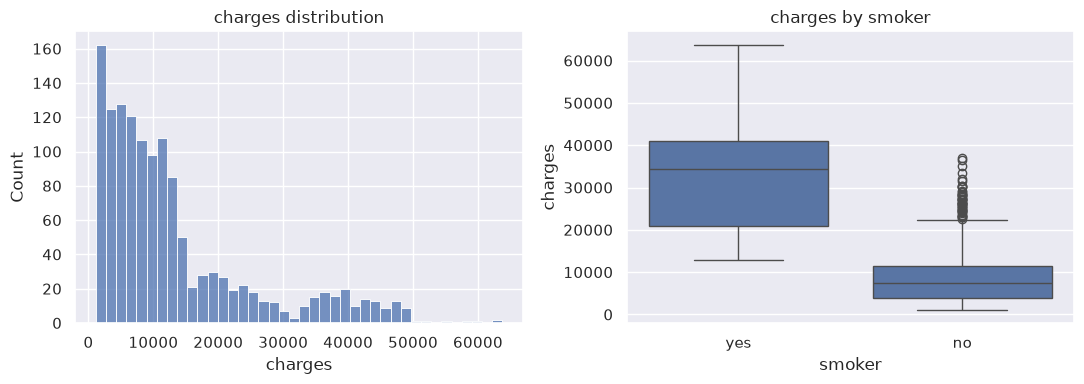

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["charges"], bins=40, ax=ax[0])
ax[0].set_title("charges distribution")
sns.boxplot(x="smoker", y="charges", data=df, ax=ax[1])
ax[1].set_title("charges by smoker")
plt.tight_layout()
plt.show()

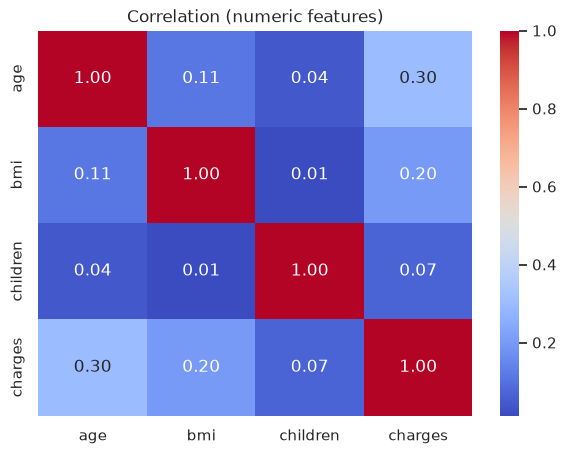

In [6]:
num = df.select_dtypes("number")
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation (numeric features)")
plt.show()

In [7]:
df.groupby("smoker")["charges"].agg(["mean", "median", "count"])

,mean,median,count
smoker,,,
no,8434.268298,7345.40530,1064
yes,32050.231832,34456.34845,274


## 2. Modeling

Train/test split (80/20), `DictVectorizer` for encoding, 5-fold CV on the training set, then evaluate the selected model on the test set.

In [8]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, train_test_split
import xgboost as xgb

TARGET = "charges"

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mae(y_true, y_pred):
    return float(mean_absolute_error(y_true, y_pred))

def cv_score(model, X, y, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    rmses, maes = [], []
    for tr, va in kf.split(X):
        m = clone(model)
        m.fit(X[tr], y[tr])
        pred = m.predict(X[va])
        rmses.append(rmse(y[va], pred))
        maes.append(mae(y[va], pred))
    return float(np.mean(rmses)), float(np.mean(maes))

In [9]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
y_train = df_train[TARGET].values
y_test = df_test[TARGET].values

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train.drop(columns=[TARGET]).to_dict(orient="records"))
X_test = dv.transform(df_test.drop(columns=[TARGET]).to_dict(orient="records"))
X_train.shape, X_test.shape

((1070, 11), (268, 11))

In [10]:
candidates = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, random_state=1, n_jobs=-1),
    "XGBoost": xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                 subsample=0.9, colsample_bytree=0.9, random_state=1, n_jobs=-1),
}

scores = {}
for name, model in candidates.items():
    r, m = cv_score(model, X_train, y_train)
    scores[name] = {"rmse_cv": round(r, 2), "mae_cv": round(m, 2)}

pd.DataFrame(scores).T

,rmse_cv,mae_cv
Dummy (mean),12074.54,9123.03
Linear Regression,6117.02,4215.50
Ridge,6116.99,4221.19
Random Forest,4900.12,2764.68
XGBoost,4883.33,2789.22


### Select the best model and evaluate on the test set

In [11]:
best_name = min(scores, key=lambda k: scores[k]["rmse_cv"])
best_model = clone(candidates[best_name])
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
print("best model:", best_name)
print("test RMSE :", round(rmse(y_test, y_pred), 2))
print("test MAE  :", round(mae(y_test, y_pred), 2))

best model: XGBoost
test RMSE : 4585.54
test MAE  : 2604.57


### Feature importance (best model)

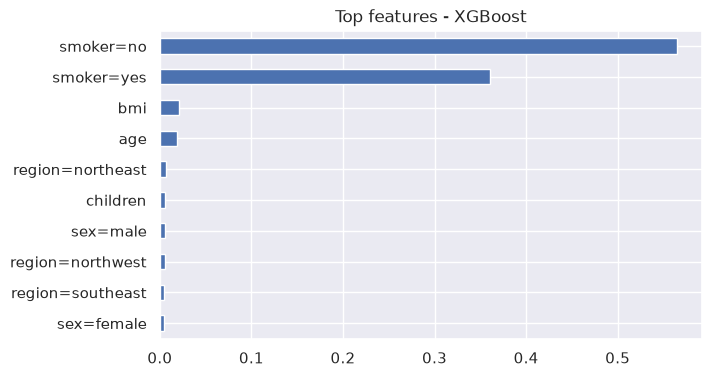

smoker=no           0.564244
smoker=yes          0.360154
bmi                 0.021140
age                 0.018677
region=northeast    0.006622
children            0.005970
sex=male            0.005476
region=northwest    0.005156
region=southeast    0.004574
sex=female          0.004084
dtype: float32

In [12]:
names = dv.get_feature_names_out()
importances = best_model.feature_importances_
imp = pd.Series(importances, index=names).sort_values(ascending=False).head(10)
imp.plot(kind="barh", figsize=(7, 4)).invert_yaxis()
plt.title(f"Top features - {best_name}")
plt.show()
imp